<a href="https://colab.research.google.com/github/SelinBeyaz01/BUS392-Steam-Project/blob/Anjani-Analysis/BUS392_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
!pip install kagglehub

In [7]:
import kagglehub
path = kagglehub.dataset_download("hubertsidorowicz/steam-games-dataset-daily-updates")

Using Colab cache for faster access to the 'steam-games-dataset-daily-updates' dataset.


In [8]:
import pandas as pd
gamesData_location = path + "/steam_games.csv"
gamesData = pd.read_csv(gamesData_location)
gamesData.head()

/tmp/ipykernel_1685/1104197516.py:3: DtypeWarning: Columns (30,31,32) have mixed types. Specify dtype option on import or set low_memory=False.
  gamesData = pd.read_csv(gamesData_location)


,app_id,name,release_date,price,price_status,estimated_owners,developers,publishers,genres,categories,...,linux,header_image,screenshots,movies,website,support_url,support_email,metacritic_url,steam_store_available,steam_spy_available
0,2582880,Northrealm Tribes,2026-10-20,0.00,free,"0 .. 20,000","[""DevSanja""]","[""DevSanja""]","[{""id"": ""4"", ""description"": ""Casual""}, {""id"": ...","[{""id"": 2, ""description"": ""Single-player""}, {""...",...,True,https://shared.akamai.steamstatic.com/store_it...,"[{""id"": 0, ""path_thumbnail"": ""https://shared.a...","[{""id"": 257460676, ""name"": ""Northrealm Tribes:...",NaN,NaN,ma.schleufe@gmx.de,NaN,True,True
1,3508520,Echoes of the Abyss,2026-10-21,0.99,paid,"0 .. 20,000","[""lijj1235666""]","[""lij1235666""]","[{""id"": ""1"", ""description"": ""Action""}, {""id"": ...","[{""id"": 2, ""description"": ""Single-player""}, {""...",...,False,https://shared.akamai.steamstatic.com/store_it...,"[{""id"": 0, ""path_thumbnail"": ""https://shared.a...","[{""id"": 257108877, ""name"": ""Bounce ball simula...",NaN,NaN,q1w2e3_r42023@qq.com,NaN,True,True
2,1508190,Finding Words,2026-10-21,3.99,paid,"0 .. 20,000","[""Odd Build""]","[""Odd Build""]","[{""id"": ""4"", ""description"": ""Casual""}]","[{""id"": 2, ""description"": ""Single-player""}, {""...",...,False,https://shared.akamai.steamstatic.com/store_it...,"[{""id"": 0, ""path_thumbnail"": ""https://shared.a...","[{""id"": 257459902, ""name"": ""Finding Words Trai...",NaN,criandomeujogo.com,criandomeujogo@hotmail.com,NaN,True,True
3,3639110,Terror In The Shadowrealms,2026-10-21,1.99,paid,"0 .. 20,000","[""Onigumo69""]","[""Onigumo69""]","[{""id"": ""4"", ""description"": ""Casual""}, {""id"": ...","[{""id"": 2, ""description"": ""Single-player""}, {""...",...,False,https://shared.akamai.steamstatic.com/store_it...,"[{""id"": 0, ""path_thumbnail"": ""https://shared.a...","[{""id"": 257421609, ""name"": ""Terror In The Shad...",NaN,NaN,onigumo69@outlook.com,NaN,True,True
4,1564060,Lighthouse of Madness,2026-10-21,13.99,paid,"0 .. 20,000","[""Flying Jack Studios""]","[""Flying Jack Productions""]","[{""id"": ""25"", ""description"": ""Adventure""}, {""i...","[{""id"": 2, ""description"": ""Single-player""}, {""...",...,False,https://shared.akamai.steamstatic.com/store_it...,"[{""id"": 0, ""path_thumbnail"": ""https://shared.a...","[{""id"": 256900399, ""name"": ""Lighthouse of Madn...",https://lighthouseofmadness.com,https://www.flyingjack.com.br,productions@flyingjack.com.br,NaN,True,True


In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

my_games = gamesData[['app_id', 'name', 'release_date', 'estimated_owners', 'positive',
                      'negative', 'recommendations', 'average_playtime_forever']].copy()
my_games = my_games.drop_duplicates(subset='app_id')
my_games['release_date'] = pd.to_datetime(my_games['release_date'], errors='coerce')

number_columns = ['positive', 'negative', 'recommendations', 'average_playtime_forever']
for column in number_columns:
    my_games[column] = pd.to_numeric(my_games[column], errors='coerce')

my_games['total_reviews'] = my_games['positive'] + my_games['negative']

def owner_midpoint(owner_range):
    try:
        low, high = str(owner_range).replace(',', '').split(' .. ')
        return (int(low) + int(high)) / 2
    except:
        return np.nan

my_games['owners'] = my_games['estimated_owners'].apply(owner_midpoint)

newest_date = my_games['release_date'].max()
my_games['age_years'] = (newest_date - my_games['release_date']).dt.days / 365

my_games = my_games[(my_games['total_reviews'] > 0) & (my_games['age_years'] >= 0.5)].copy()

my_games['positive_per_year'] = my_games['positive'] / my_games['age_years']
my_games['negative_per_year'] = my_games['negative'] / my_games['age_years']
my_games['positive_per_month'] = my_games['positive_per_year'] / 12
my_games['negative_per_month'] = my_games['negative_per_year'] / 12

def age_group(years):
    if years < 2:
        return '1) Under 2 years'
    elif years < 5:
        return '2) 2-5 years'
    elif years < 10:
        return '3) 5-10 years'
    else:
        return '4) 10+ years'

my_games['age_group'] = my_games['age_years'].apply(age_group)

print("Games in my analysis:", len(my_games))

Games in my analysis: 83029


In [25]:
age_table = my_games.groupby('age_group')[['positive', 'negative',
                                           'positive_per_year', 'negative_per_year',
                                           'positive_per_month', 'negative_per_month']].mean().round(1)
age_table

,positive,negative,positive_per_year,negative_per_year,positive_per_month,negative_per_month
age_group,,,,,,
1) Under 2 years,497.3,88.3,336.5,57.7,28.0,4.8
2) 2-5 years,727.7,134.2,229.4,41.2,19.1,3.4
3) 5-10 years,1327.6,237.0,184.4,32.8,15.4,2.7
4) 10+ years,5690.7,781.0,436.8,61.9,36.4,5.2


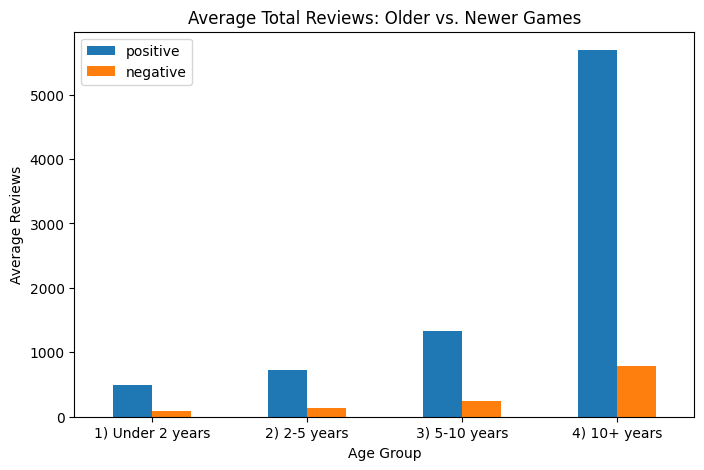

In [26]:
age_table[['positive', 'negative']].plot(kind='bar', figsize=(8, 5))
plt.title('Average Total Reviews: Older vs. Newer Games')
plt.xlabel('Age Group')
plt.ylabel('Average Reviews')
plt.xticks(rotation=0)
plt.show()

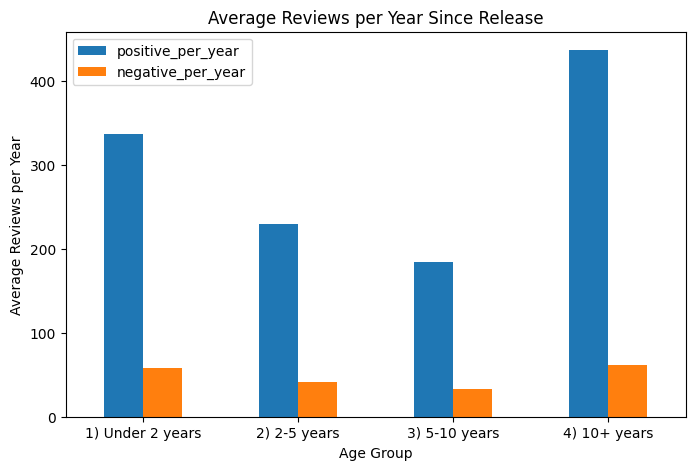

In [27]:
age_table[['positive_per_year', 'negative_per_year']].plot(kind='bar', figsize=(8, 5))
plt.title('Average Reviews per Year Since Release')
plt.xlabel('Age Group')
plt.ylabel('Average Reviews per Year')
plt.xticks(rotation=0)
plt.show()

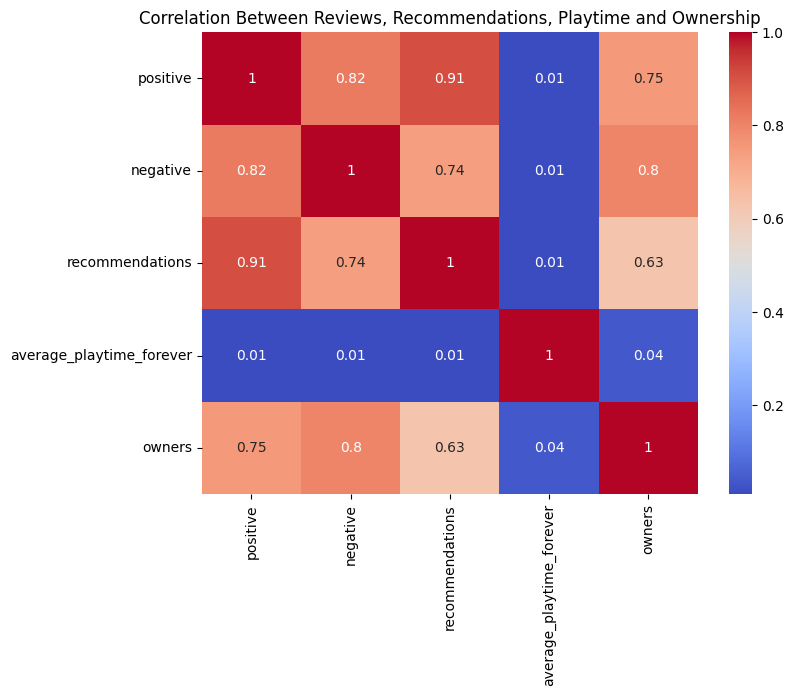

,positive,negative,recommendations,average_playtime_forever,owners
positive,1.00,0.82,0.91,0.01,0.75
negative,0.82,1.00,0.74,0.01,0.80
recommendations,0.91,0.74,1.00,0.01,0.63
average_playtime_forever,0.01,0.01,0.01,1.00,0.04
owners,0.75,0.80,0.63,0.04,1.00


In [28]:
measures = ['positive', 'negative', 'recommendations', 'average_playtime_forever', 'owners']

correlation_table = my_games[measures].corr().round(2)

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_table, annot=True, cmap='coolwarm')
plt.title('Correlation Between Reviews, Recommendations, Playtime and Ownership')
plt.show()

correlation_table

In [29]:
compare_list = ['recommendations', 'average_playtime_forever', 'owners']

for measure in compare_list:
    value = correlation_table.loc['positive', measure]
    if value >= 0.5:
        print(f"Positive reviews and {measure}: {value} -> strong, they agree")
    elif value >= 0.2:
        print(f"Positive reviews and {measure}: {value} -> moderate, they somewhat agree")
    else:
        print(f"Positive reviews and {measure}: {value} -> weak, they disagree")

print("Share of games with playtime above 0:", round((my_games['average_playtime_forever'] > 0).mean(), 3))

Positive reviews and recommendations: 0.91 -> strong, they agree
Positive reviews and average_playtime_forever: 0.01 -> weak, they disagree
Positive reviews and owners: 0.75 -> strong, they agree
Share of games with playtime above 0: 0.088
